<a href="https://colab.research.google.com/github/FelipeCostadeSouza/calc_numtrue/blob/main/Tarefa_Gauss.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Felipe Costa de Souza 187396

https://drive.google.com/drive/folders/1Bei9aHC7wQZXEvTFyR3HLpDTc88Q8lKl

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

def gauss_seidel_solver(A, b, x0, tol=1e-5, max_iter=100):

  A = np.array(A, dtype=float)
  b = np.array(b, dtype=float)
  x = np.array(x0, dtype=float)
  n = len(b)

  historico_iteracoes = [np.copy(x)]
  erros = []

  for k in range(1, max_iter + 1):
    x_anterior = np.copy(x)

    for i in range(n):
      soma = 0
      for j in range(n):
        if j != i:
          soma += A[i, j] * x[j]  # Usa o valor mais recente (atual ou anterior)
      x[i] = (b[i] - soma) / A[i, i]

    historico_iteracoes.append(np.copy(x))

    erro = np.max(np.abs(x - x_anterior))
    erros.append(erro)

    if erro < tol:
      print(f"Convergência atingida na iteração {k} com erro {erro:.2e}")
      return x, k, historico_iteracoes, erros

  print("Número máximo de iterações atingido sem convergir.")
  return x, max_iter, historico_iteracoes, erros


A = [[10, -1, 2], [-1, 11, -1], [2, -1, 10]]

b = [6, 22, -10]

x0 = [0.0, 0.0, 0.0]

solucao, num_iter, historico, lista_erros = gauss_seidel_solver(A, b, x0)

print(f"\nNúmero de iterações realizadas: {num_iter}")
print(
    "Solução aproximada obtida:"
    f" x = {solucao[0]:.6f}, y = {solucao[1]:.6f}, z = {solucao[2]:.6f}"
)

Convergência atingida na iteração 6 com erro 1.26e-06

Número de iterações realizadas: 6
Solução aproximada obtida: x = 1.000000, y = 2.000000, z = -1.000000


In [ ]:
print(
    f"{'k':<4} | {'x^(k)':<10} | {'y^(k)':<10} | {'z^(k)':<10} |"
    f" {'||x^(k) - x^(k-1)||_inf':<22}"
)
print("-" * 65)

print(
    f"{0:<4} | {historico[0][0]:<10.5f} | {historico[0][1]:<10.5f} |"
    f" {historico[0][2]:<10.5f} | {'-'}"
)

for k in range(1, len(lista_erros) + 1):
  xk, yk, zk = historico[k]
  err = lista_erros[k - 1]
  print(f"{k:<4} | {xk:<10.5f} | {yk:<10.5f} | {zk:<10.5f} | {err:<22.5e}")

k    | x^(k)      | y^(k)      | z^(k)      | ||x^(k) - x^(k-1)||_inf
-----------------------------------------------------------------
0    | 0.00000    | 0.00000    | 0.00000    | -
1    | 0.60000    | 2.05455    | -0.91455   | 2.05455e+00           
2    | 0.98836    | 2.00671    | -0.99700   | 3.88364e-01           
3    | 1.00007    | 2.00028    | -0.99999   | 1.17078e-02           
4    | 1.00003    | 2.00000    | -1.00000   | 2.75540e-04           
5    | 1.00000    | 2.00000    | -1.00000   | 2.38922e-05           
6    | 1.00000    | 2.00000    | -1.00000   | 1.26261e-06           


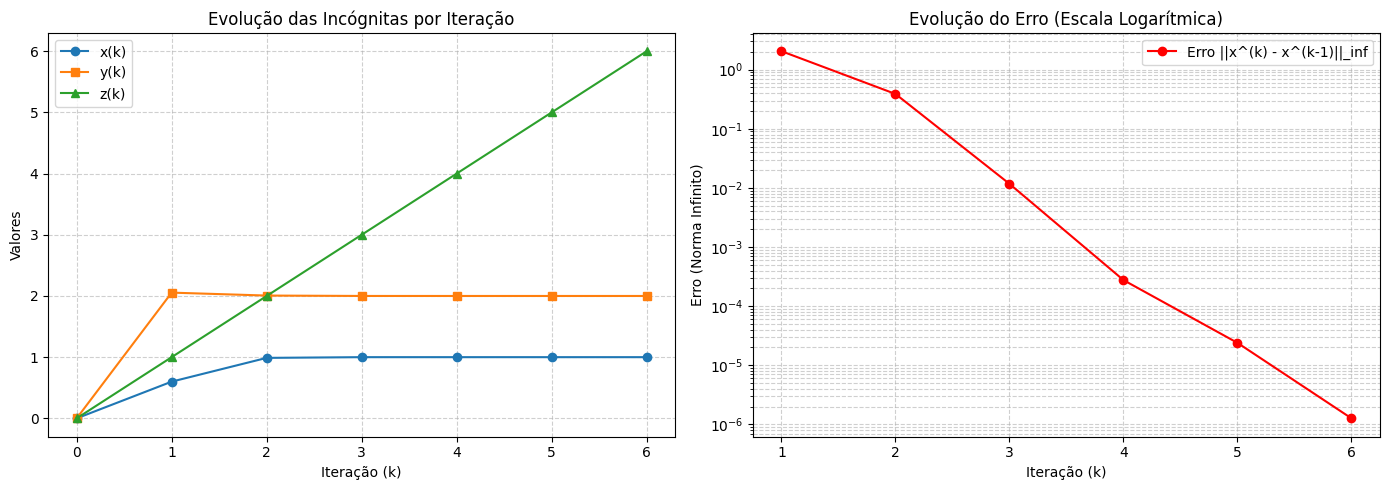

In [ ]:

iteracoes_vals = list(range(len(historico)))
x_vals = [h[0] for h in historico]
y_vals = [h[1] for h in historico]
z_vals = [h[2] for h in historico]

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(iteracoes_vals, x_vals, marker="o", label="x(k)")
plt.plot(iteracoes_vals, y_vals, marker="s", label="y(k)")
plt.plot(iteracoes_vals, marker="^", label="z(k)")
plt.title("Evolução das Incógnitas por Iteração")
plt.xlabel("Iteração (k)")
plt.ylabel("Valores")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(
    range(1, len(lista_erros) + 1),
    lista_erros,
    marker="o",
    color="red",
    label="Erro ||x^(k) - x^(k-1)||_inf",
)
plt.yscale("log")
plt.title("Evolução do Erro (Escala Logarítmica)")
plt.xlabel("Iteração (k)")
plt.ylabel("Erro (Norma Infinito)")
plt.grid(True, which="both", linestyle="--", alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()